[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/05_Leonardo.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**TCE11616 - Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 05 — GRADIENTES E OS "BOTÕES" DO TREINAMENTO
---

Nas últimas aulas, usamos sempre as mesmas linhas mágicas: `perda.backward()` e `otimizador.step()`. 

Vamos entender, de forma intuitiva, o que elas fazem e aprender a regular os principais "botões" do treinamento.

Veremos:
- o que é o **gradiente** e como o PyTorch o calcula;
- como o otimizador usa o gradiente para **descer** a perda;
- o efeito da **taxa de aprendizado** (`lr`);
- os otimizadores **SGD** e **Adam**;
- o efeito do **tamanho do lote** e do **número de épocas**.
- por que o **ponto de partida** dos pesos (a **inicialização**) pode decidir se uma rede profunda aprende ou não.

## 0. Importando as bibliotecas

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. O que é o gradiente?
---

Imagine que você está em um morro, no meio da neblina, e quer chegar ao ponto mais baixo. Você não vê o vale, mas sente a **inclinação** do chão sob seus pés. Uma estratégia simples: dar um passo para o lado em que o chão **desce**.

O treinamento da rede segue um processo semelhante: os parâmetros são a sua posição, a perda é a altura do terreno, e o otimizador dá passos morro abaixo.

### Um exemplo com um único parâmetro

Vamos minimizar uma "perda" bem simples:

$$ \text{perda}(w) = (w - 3)^2 $$

O menor valor (zero) acontece em $w = 3$. Vamos ver se o PyTorch encontra isso sozinho.

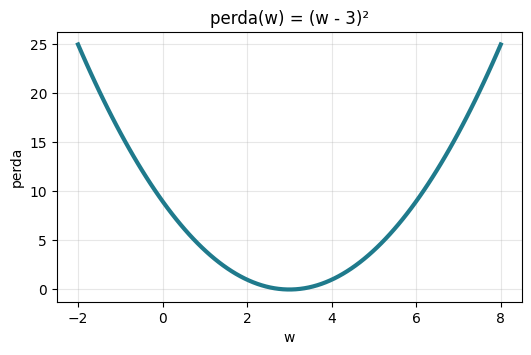

In [2]:
w_valores = torch.linspace(-2, 8, 100)

plt.figure(figsize=(6, 3.5))
plt.plot(w_valores, (w_valores - 3) ** 2, color=AZUL, linewidth=3)
plt.xlabel("w"); plt.ylabel("perda"); plt.title("perda(w) = (w - 3)²"); plt.grid(alpha=0.3)
plt.show()

O argumento `requires_grad=True` pede ao PyTorch para **acompanhar** as contas feitas com `w`. Depois de calcular a perda, `perda.backward()` calcula a inclinação e a guarda em `w.grad`.

In [3]:
w = torch.tensor(0.0, requires_grad=True)     # ponto de partida: w = 0

perda = (w - 3) ** 2
perda.backward()                               # calcula o gradiente

print("w        =", w.item())
print("perda    =", perda.item())
print("gradiente=", w.grad.item())

w        = 0.0
perda    = 9.0
gradiente= -6.0


w.grad retornou **−6**. De fato, a derivada de $(w-3)^2$ é $2(w-3)$, que vale $-6$ em $w = 0$.

**Assim, a perda **diminui** se aumentarmos $w$.** 

### Gradiente descendente

A regra da **descida de gradiente** é: andar um pouquinho **contra** o gradiente.

$$ w \leftarrow w - \text{lr} \times \text{gradiente} $$

O `lr` (*learning rate*, **taxa de aprendizado**) é o tamanho do passo.

In [4]:
w = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for passo in range(10):
    perda = (w - 3) ** 2
    perda.backward()

    with torch.no_grad():
        w -= lr * w.grad        # dá um passo contra o gradiente
    
    w.grad.zero_()              # zera o gradiente para o próximo passo

    print(f"passo {passo + 1:2d}: w = {w.item():.4f} | perda = {perda.item():.4f}")

passo  1: w = 0.6000 | perda = 9.0000
passo  2: w = 1.0800 | perda = 5.7600
passo  3: w = 1.4640 | perda = 3.6864
passo  4: w = 1.7712 | perda = 2.3593
passo  5: w = 2.0170 | perda = 1.5099
passo  6: w = 2.2136 | perda = 0.9664
passo  7: w = 2.3709 | perda = 0.6185
passo  8: w = 2.4967 | perda = 0.3958
passo  9: w = 2.5973 | perda = 0.2533
passo 10: w = 2.6779 | perda = 0.1621


O $w$ caminha em direção a 3 e a perda cai a cada passo.

**É exatamente isso que o otimizador faz.** As três linhas do nosso laço de treino correspondem a esse código:

| Laço de treino | O que faz |
|---|---|
| `otimizador.zero_grad()` | `w.grad.zero_()` para todos os parâmetros |
| `perda.backward()` | calcula o gradiente de todos os parâmetros |
| `otimizador.step()` | `w -= lr * w.grad` para todos os parâmetros |

Uma rede neural tem milhares de parâmetros em vez de um, mas a ideia é a mesma.

### O tamanho do passo importa

Vamos repetir a descida com três taxas de aprendizado diferentes. Desta vez usamos o otimizador `torch.optim.SGD`, que faz a mesma conta para nós.

In [5]:
# função auxiliar

def descer(lr, passos=15):
    w = torch.tensor(0.0, requires_grad=True)
    otimizador = torch.optim.SGD([w], lr=lr)
    caminho = [w.item()]
    for passo in range(passos):
        perda = (w - 3) ** 2
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        caminho.append(w.item())
    return caminho

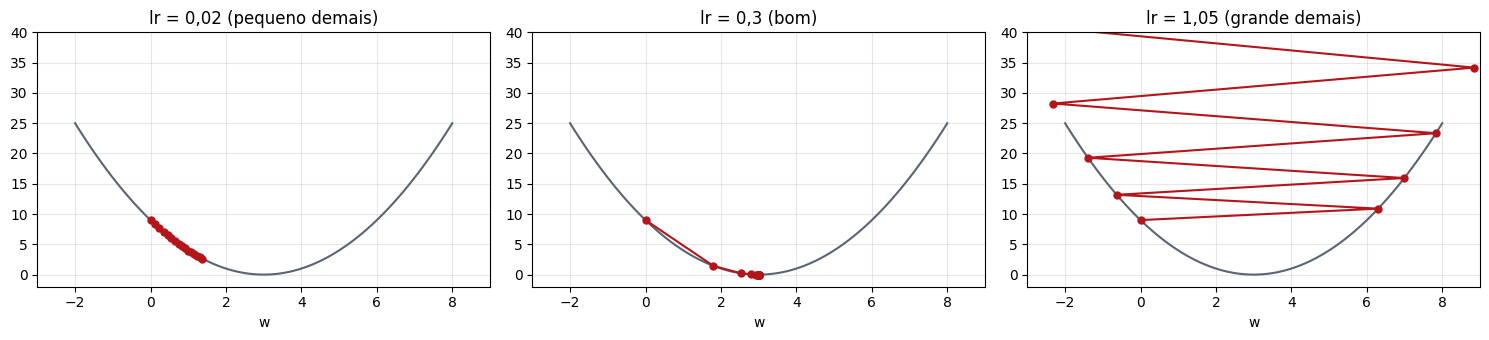

In [6]:
plt.figure(figsize=(15, 3.5))

for i, (lr, titulo) in enumerate([(0.02, "lr = 0,02 (pequeno demais)"),
                                  (0.3,  "lr = 0,3 (bom)"),
                                  (1.05, "lr = 1,05 (grande demais)")]):
    caminho = np.array(descer(lr))
    plt.subplot(1, 3, i + 1)
    plt.plot(w_valores, (w_valores - 3) ** 2, color=CINZA)
    plt.plot(caminho, (caminho - 3) ** 2, "o-", color=VERMELHO, markersize=5)
    plt.title(titulo); plt.xlabel("w"); plt.ylim(-2, 40); plt.xlim(-3, 9); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **lr pequeno demais**: os passos são minúsculos; depois de 15 passos ainda estamos longe do fundo.
- **lr bom**: chegamos perto de $w = 3$ rapidamente.
- **lr grande demais**: cada passo "pula" por cima do vale e cai mais alto do outro lado. A perda **aumenta** e o treino **diverge**.

Escolher a taxa de aprendizado é o ajuste mais importante do treinamento.

---
## 2. Um conjunto de dados para experimentar
---

Usaremos o conjunto **digits** do scikit-learn: 1 797 imagens pequenas ($8 \times 8$ pixels) de dígitos de 0 a 9. 

É um "MNIST em miniatura".

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digitos = load_digits()
print("formato dos dados:", digitos.data.shape)    # 1797 imagens, cada uma com 64 pixels

formato dos dados: (1797, 64)


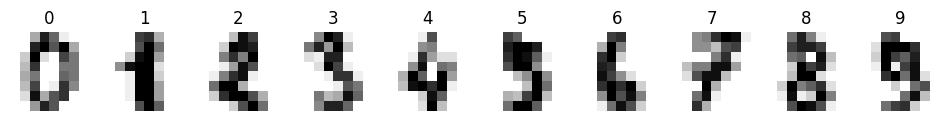

In [8]:
plt.figure(figsize=(12, 2.2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(digitos.images[i], cmap="gray_r")
    plt.title(digitos.target[i]); plt.axis("off")
plt.show()

Iniciaremos separando o conjunto de dados nos conjuntos de treino e teste. Então, realizaremos a conversão para tensores. 

Os pixels vão de 0 a 16; dividimos por 16 para que fiquem entre 0 e 1. 

Os rótulos de classificação com várias classes são **inteiros**, por isso usamos `dtype=torch.long`.

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(digitos.data, digitos.target, test_size=0.3, random_state=42)

X_treino = torch.tensor(X_tr / 16, dtype=torch.float32)
X_teste  = torch.tensor(X_te / 16, dtype=torch.float32)
Y_treino = torch.tensor(y_tr, dtype=torch.long)
Y_teste  = torch.tensor(y_te, dtype=torch.long)

print("X_treino:", X_treino.shape, "| Y_treino:", Y_treino.shape)

X_treino: torch.Size([1257, 64]) | Y_treino: torch.Size([1257])


Duas funções auxiliares: uma cria a rede (sempre a mesma, para comparar só o treino) e outra mede a acurácia.

In [10]:
def criar_rede():
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))


def acuracia(modelo, X, Y):
    with torch.no_grad():
        previsto = modelo(X).argmax(dim=1)
    return (previsto == Y).float().mean().item()

E a função de treino, que agora recebe o **otimizador** como argumento. Assim podemos testar otimizadores e taxas de aprendizado diferentes sem mudar o laço.

In [11]:
def treinar(modelo, otimizador, epocas=200):
    perda_fn = nn.CrossEntropyLoss()
    historico = []
    for epoca in range(epocas):
        perda = perda_fn(modelo(X_treino), Y_treino)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())
    return historico

---
## 3. Botão 1: a taxa de aprendizado
---

Treinamos a mesma rede com SGD e quatro taxas de aprendizado.

lr = 0.001  | perda final = 2.295 | acurácia no teste = 12.4%


lr = 0.01   | perda final = 2.188 | acurácia no teste = 45.0%
lr = 0.1    | perda final = 0.488 | acurácia no teste = 90.9%


lr = 1.0    | perda final = 0.055 | acurácia no teste = 97.6%


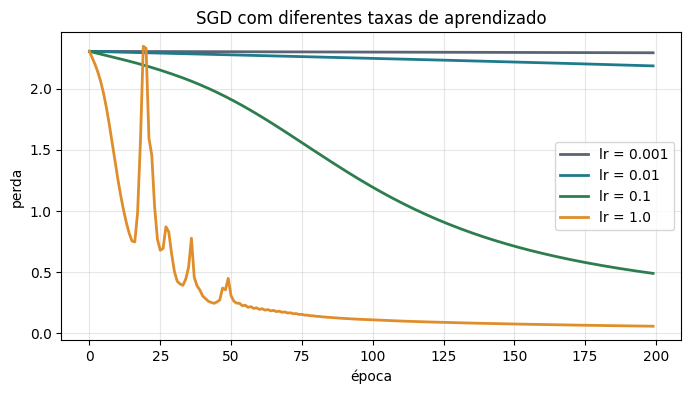

In [12]:
plt.figure(figsize=(8, 4))
for lr, cor in zip([0.001, 0.01, 0.1, 1.0], [CINZA, AZUL, VERDE, LARANJA]):
    torch.manual_seed(42)
    rede = criar_rede()
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=lr))
    print(f"lr = {lr:<6} | perda final = {historico[-1]:.3f} | acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")
    plt.plot(historico, color=cor, linewidth=2, label=f"lr = {lr}")

plt.xlabel("época"); plt.ylabel("perda"); plt.title("SGD com diferentes taxas de aprendizado")
plt.legend(); plt.grid(alpha=0.3); plt.show()

O mesmo comportamento do exemplo de uma variável: com `lr` pequeno a perda quase não sai do lugar em 200 épocas; aumentando o `lr`, o treino fica bem mais rápido.

---
## 4. Botão 2: o otimizador (SGD × Adam)
---

O **Adam** é uma versão "esperta" da descida de gradiente: ele ajusta o tamanho do passo de cada parâmetro automaticamente. Na prática, ele costuma funcionar bem em uma faixa maior de taxas de aprendizado.

In [13]:
print(f"{'lr':>7} | {'SGD':>6} | {'Adam':>6}")
print("-" * 26)
for lr in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    resultados = []
    for Otimizador in [torch.optim.SGD, torch.optim.Adam]:
        torch.manual_seed(42)
        rede = criar_rede()
        treinar(rede, Otimizador(rede.parameters(), lr=lr))
        resultados.append(acuracia(rede, X_teste, Y_teste))
    print(f"{lr:>7} | {resultados[0]:>6.1%} | {resultados[1]:>6.1%}")

     lr |    SGD |   Adam
--------------------------


 0.0001 |  12.2% |  56.9%


  0.001 |  12.4% |  93.7%


   0.01 |  45.0% |  97.6%


    0.1 |  90.9% |  97.0%


    1.0 |  97.6% |  14.4%


Repare que:

- o SGD só funciona bem com taxas de aprendizado **altas** neste problema;
- o Adam funciona bem com taxas **entre 0,001 e 0,1**, mas também **falha** se o `lr` for grande demais (1,0).

Não existe taxa de aprendizado universal: cada problema e cada otimizador têm a sua faixa boa.

> **Regra prática:** comece com `torch.optim.Adam(modelo.parameters(), lr=0.001)`. Se a perda cair devagar demais, aumente o `lr` 10 vezes; se a perda ficar instável ou aumentar, diminua.

---
## 5. Botão 3: o tamanho do lote
---

Até agora, em cada passo a rede via **todos** os dados de treino. Na Aula 04 (MNIST), usamos **lotes** de 64 imagens com o `DataLoader`. Qual a diferença?

- **Lote completo:** 1 passo por época, com o gradiente "exato".
- **Lotes pequenos:** muitos passos por época, cada um com um gradiente aproximado (calculado com poucos exemplos).

Vamos comparar, com o mesmo número de épocas, usando o Adam.

In [14]:
from torch.utils.data import TensorDataset, DataLoader

dados_treino = TensorDataset(X_treino, Y_treino)     # junta X e Y em um único conjunto


def treinar_em_lotes(modelo, tamanho_lote, epocas=30):
    carregador = DataLoader(dados_treino, batch_size=tamanho_lote, shuffle=True)
    perda_fn = nn.CrossEntropyLoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    acuracias = []
    for epoca in range(epocas):
        for xb, yb in carregador:
            perda = perda_fn(modelo(xb), yb)
            otimizador.zero_grad()
            perda.backward()
            otimizador.step()
        acuracias.append(acuracia(modelo, X_teste, Y_teste))     # mede ao fim de cada época
    return acuracias

lote = 8 (158 passos por época)          acurácia final = 96.7%


lote = 32 (40 passos por época)          acurácia final = 95.9%


lote = 128 (10 passos por época)         acurácia final = 93.7%
lote = 1257 (1 passos por época)         acurácia final = 68.3%


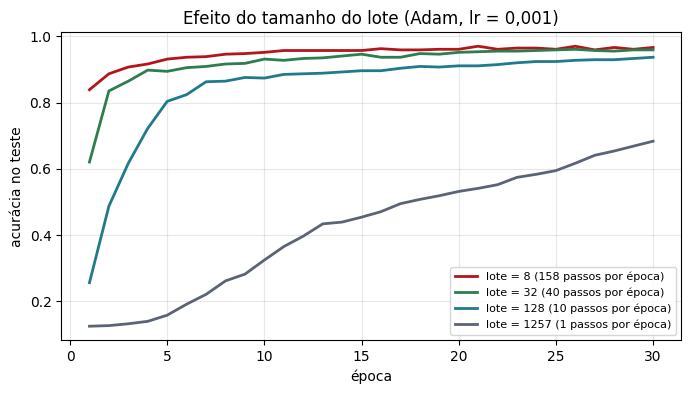

In [15]:
plt.figure(figsize=(8, 4))
for tamanho, cor in zip([8, 32, 128, len(X_treino)], [VERMELHO, VERDE, AZUL, CINZA]):
    torch.manual_seed(42)
    rede = criar_rede()
    acuracias = treinar_em_lotes(rede, tamanho)
    n_passos = len(DataLoader(dados_treino, batch_size=tamanho))
    rotulo = f"lote = {tamanho} ({n_passos} passos por época)"
    plt.plot(range(1, 31), acuracias, color=cor, linewidth=2, label=rotulo)
    print(f"{rotulo:<40} acurácia final = {acuracias[-1]:.1%}")

plt.xlabel("época"); plt.ylabel("acurácia no teste"); plt.title("Efeito do tamanho do lote (Adam, lr = 0,001)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

Com lotes pequenos, a rede dá **muito mais passos** por época e aprende em menos épocas. Com o lote completo, ela dá só um passo por época e, em 30 épocas, fica bem atrás (cerca de 70% de acurácia).

Por outro lado, lotes muito pequenos deixam cada passo mais "barulhento" e não aproveitam bem o processamento em paralelo do computador (especialmente da GPU). Na prática, valores entre **32 e 256** são os mais usados.

---
## 6. Botão 4: o número de épocas
---

Quantas épocas treinar? Vamos acompanhar a acurácia de **treino** e de **teste** ao longo de muitas épocas.

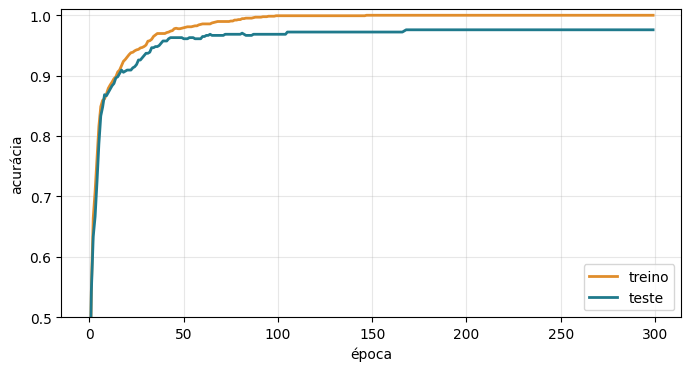

acurácia final -> treino: 100.0% | teste: 97.6%


In [16]:
torch.manual_seed(42)
rede = criar_rede()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)
perda_fn = nn.CrossEntropyLoss()

acc_treino, acc_teste = [], []
for epoca in range(300):
    perda = perda_fn(rede(X_treino), Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()
    acc_treino.append(acuracia(rede, X_treino, Y_treino))
    acc_teste.append(acuracia(rede, X_teste, Y_teste))

plt.figure(figsize=(8, 4))
plt.plot(acc_treino, color=LARANJA, linewidth=2, label="treino")
plt.plot(acc_teste, color=AZUL, linewidth=2, label="teste")
plt.xlabel("época"); plt.ylabel("acurácia"); plt.ylim(0.5, 1.01)
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"acurácia final -> treino: {acc_treino[-1]:.1%} | teste: {acc_teste[-1]:.1%}")

- No começo, as duas curvas sobem juntas: a rede está aprendendo padrões úteis.
- Depois, a acurácia de treino chega a **100%**, enquanto a de teste para de melhorar. A partir daí, treinar mais não ajuda.

A diferença entre treino e teste é um sinal importante, que estudaremos com cuidado nas próximas aulas.

---
## 7. Botão 5: a inicialização
---

Antes do treino começar, a rede precisa de valores para **todos** os seus pesos. O PyTorch os sorteia ao criar cada camada: é a **inicialização**. Na imagem do morro da Seção 1, a inicialização é o **ponto de partida** da descida.

Veja: a mesma camada criada com duas sementes diferentes começa com pesos diferentes.

In [17]:
torch.manual_seed(0)
camada_a = nn.Linear(64, 64)
torch.manual_seed(1)
camada_b = nn.Linear(64, 64)

print("alguns pesos com semente 0:", camada_a.weight[0, :5].detach())
print("alguns pesos com semente 1:", camada_b.weight[0, :5].detach())

alguns pesos com semente 0: tensor([-0.0009,  0.0671, -0.1029, -0.0920, -0.0481])
alguns pesos com semente 1: tensor([ 0.0644, -0.0552, -0.0242,  0.0587, -0.1177])


### A sorte conta um pouco

Partindo de pontos diferentes, a descida termina em lugares um pouco diferentes. Treinando a rede da Seção 2 com 5 sementes:

In [18]:
for semente in range(5):
    torch.manual_seed(semente)
    rede = criar_rede()
    treinar(rede, torch.optim.Adam(rede.parameters(), lr=0.01))
    print(f"semente {semente}: acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")

semente 0: acurácia no teste = 97.6%


semente 1: acurácia no teste = 98.0%


semente 2: acurácia no teste = 97.2%


semente 3: acurácia no teste = 97.6%


semente 4: acurácia no teste = 97.2%


As diferenças são pequenas aqui, mas lembre disso ao comparar modelos: uma diferença de poucos décimos pode ser só sorte.

### O tamanho dos pesos iniciais importa muito

Mais importante que a sorte é a **escala** dos números sorteados. Em uma rede com uma camada oculta, como a de cima, quase qualquer escolha razoável funciona. Em uma rede **profunda**, não.

Vamos montar uma rede com **10 camadas ocultas** e inicializá-la de quatro formas, usando as funções do módulo `nn.init`:

| Modo | O que faz |
|---|---|
| `"padrão"` | deixa os pesos sorteados pelo próprio PyTorch |
| `"pequena"` | pesos sorteados com desvio **0,01** (pequenos demais) |
| `"grande"` | pesos sorteados com desvio **1,0** (grandes demais) |
| `"He"` | `nn.init.kaiming_normal_`: desvio escolhido de acordo com o tamanho da camada, pensado para redes com ReLU |

In [19]:
def criar_rede_profunda(n_camadas=10):
    camadas = [nn.Linear(64, 64), nn.ReLU()]
    for i in range(n_camadas - 1):
        camadas += [nn.Linear(64, 64), nn.ReLU()]
    camadas.append(nn.Linear(64, 10))
    return nn.Sequential(*camadas)


def inicializar(rede, modo):
    for camada in rede:
        if isinstance(camada, nn.Linear):            # só as camadas Linear têm pesos
            if modo == "pequena":
                nn.init.normal_(camada.weight, mean=0.0, std=0.01)
            elif modo == "grande":
                nn.init.normal_(camada.weight, mean=0.0, std=1.0)
            elif modo == "He":
                nn.init.kaiming_normal_(camada.weight)
            if modo != "padrão":
                nn.init.zeros_(camada.bias)          # vieses começam em zero
    return rede


modos = ["padrão", "pequena", "grande", "He"]
cores_modo = {"padrão": CINZA, "pequena": AZUL, "grande": VERMELHO, "He": VERDE}

### O sinal ao longo da rede

Antes de treinar, vamos passar os dados de treino pela rede e medir, depois de cada camada, o **tamanho** dos números que saem (o desvio-padrão). É o mesmo laço `for camada in rede` que usamos na Aula 08 para ver os formatos.

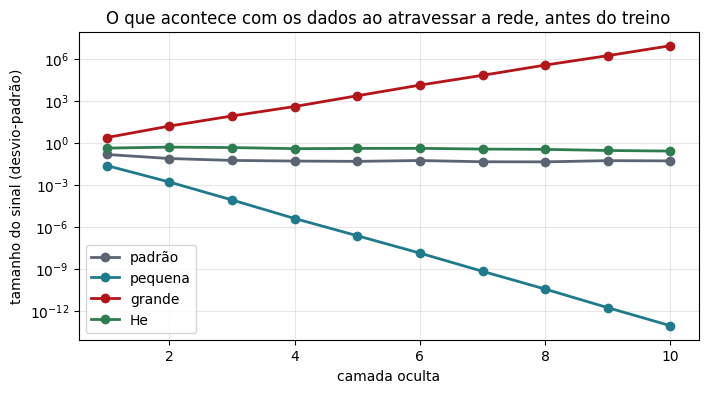

In [20]:
plt.figure(figsize=(8, 4))
for modo in modos:
    torch.manual_seed(42)
    rede = inicializar(criar_rede_profunda(), modo)

    tamanhos = []
    h = X_treino
    with torch.no_grad():
        for camada in rede:
            h = camada(h)
            if isinstance(camada, nn.ReLU):
                tamanhos.append(h.std().item())

    plt.plot(range(1, 11), tamanhos, "o-", color=cores_modo[modo], linewidth=2, label=modo)

plt.yscale("log")
plt.xlabel("camada oculta"); plt.ylabel("tamanho do sinal (desvio-padrão)")
plt.title("O que acontece com os dados ao atravessar a rede, antes do treino")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

Repare na escala logarítmica do eixo vertical (cada marca é 10 vezes a anterior):

- **pesos pequenos**: a cada camada o sinal encolhe; depois de 10 camadas ele praticamente **some**;
- **pesos grandes**: a cada camada o sinal cresce; depois de 10 camadas ele **explode** para milhões;
- **padrão do PyTorch**: o sinal não some, mas fica cerca de 100 vezes menor que com He já nas primeiras camadas;
- **He**: o sinal se mantém do mesmo tamanho do começo ao fim.

E o gradiente, que percorre a rede **de trás para frente**, sofre o mesmo problema: some ou explode. Sem gradiente útil, a rede não sabe como corrigir os pesos.

### O efeito no treino

Treinamos as quatro versões com o SGD (`lr = 0,1`) e a função `treinar` da Seção 2:

padrão   | perda final = 2.302 | acurácia no teste = 9.3%


pequena  | perda final = 2.302 | acurácia no teste = 9.3%


grande   | perda final = nan | acurácia no teste = 9.8%


He       | perda final = 0.415 | acurácia no teste = 84.6%


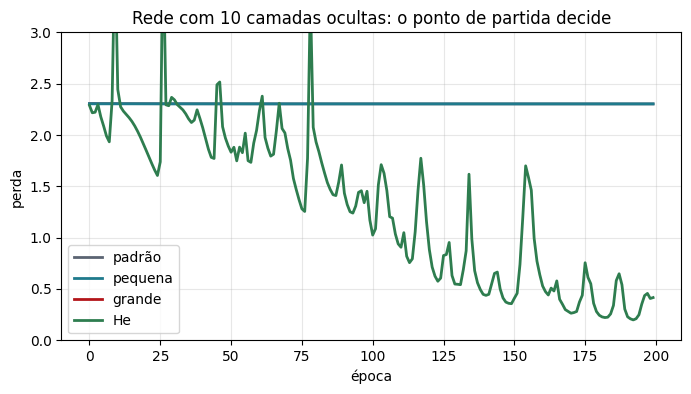

In [21]:
plt.figure(figsize=(8, 4))
for modo in modos:
    torch.manual_seed(42)
    rede = inicializar(criar_rede_profunda(), modo)
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=0.1))
    plt.plot(historico, color=cores_modo[modo], linewidth=2, label=modo)
    print(f"{modo:<8} | perda final = {historico[-1]:.3f} | acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")

plt.ylim(0, 3)
plt.xlabel("época"); plt.ylabel("perda")
plt.title("Rede com 10 camadas ocultas: o ponto de partida decide")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

- Com **pesos grandes**, a perda explode (passa de milhões) e depois vira `nan` (*not a number*): o treino quebra. Por isso a curva vermelha nem aparece no gráfico.
- Com **pesos pequenos**, a perda fica parada em 2,3: a rede não aprende nada (acurácia de ~10%, o mesmo que chutar um dígito ao acaso).
- Com o **padrão do PyTorch**, acontece o mesmo nesta rede profunda: a curva cinza fica escondida atrás da azul, parada em 2,3.
- Com a inicialização de **He**, a rede treina e acerta cerca de 95%. (Os picos na curva verde vêm do passo grande, `lr = 0,1`, em uma rede profunda; mesmo assim a tendência é de queda.)

### Como usar na prática

A regra prática é simples:

| Situação | Inicialização |
|---|---|
| redes com poucas camadas (como nas Aulas 03 e 04) | o **padrão** do PyTorch funciona bem; não precisa fazer nada |
| redes profundas com ReLU | **He**: `nn.init.kaiming_normal_(camada.weight)` |
| redes profundas com tanh ou sigmoide | **Xavier**: `nn.init.xavier_normal_(camada.weight)` |

Para aplicar, basta percorrer as camadas logo depois de criar a rede, como fizemos na função `inicializar`. 

Para redes **muito** profundas (dezenas ou centenas de camadas), a inicialização sozinha não basta: entram as **conexões residuais** e a **normalização por lote**..

---
## Exercícios
---

**1.** Na Seção 1, troque a perda por $(w + 1)^2$. Para onde o $w$ deve ir? Confira executando o laço.

**2.** Na Seção 3, teste o SGD com `lr = 3.0`. O treino ainda funciona?

**3.** Na Seção 5, treine com lote completo por **300** épocas em vez de 30. Ele alcança os lotes pequenos?

**4.** Na Seção 6, troque o `lr` para `0.001`. Quantas épocas são necessárias para a acurácia de teste passar de 90%?

**5.** Na Seção 7, crie um modo de inicialização com desvio **0,1** e outro com **0,3**. Algum deles faz a rede de 10 camadas treinar? (Para comparar: a inicialização de He usa desvio $\sqrt{2/64} \approx 0{,}18$ nessas camadas.)

**6.** Repita o treino da Seção 7 trocando o SGD pelo Adam (`lr=0.001`). Quais inicializações passam a funcionar? O Adam resolve tudo?

---
# RESOLUÇÃO DOS EXERCÍCIOS
---

**Aluno:** Leonardo

Nas células abaixo resolvo os seis exercícios. Em todos os experimentos com redes, fixo a semente antes de criar cada modelo. Assim, os modelos comparados partem dos mesmos pesos, e a única diferença é a mudança pedida. Quando a conclusão poderia depender da sorte, repito o experimento com várias sementes.

---
### Exercício 1 — Mudando a perda para $(w + 1)^2$

> Na Seção 1, troque a perda por $(w + 1)^2$. Para onde o $w$ deve ir? Confira executando o laço.

**Previsão antes de executar.** A perda $(w+1)^2$ é sempre maior ou igual a zero e só vale zero quando $w + 1 = 0$. Portanto o $w$ deve ir para **$w = -1$**.

A derivada é $2(w+1)$. Em $w = 0$ ela vale $+2$. Agora o gradiente é **positivo**, então a perda diminui se **diminuirmos** $w$. A descida deve andar para a esquerda, ao contrário do exemplo da aula.

In [22]:
w = torch.tensor(0.0, requires_grad=True)
perda = (w + 1) ** 2
perda.backward()
print("gradiente em w = 0:", w.grad.item(), "  (esperado: 2 * (0 + 1) = 2)\n")

w = torch.tensor(0.0, requires_grad=True)
lr = 0.1
caminho_ex1 = [w.item()]

for passo in range(10):
    perda = (w + 1) ** 2
    perda.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()
    caminho_ex1.append(w.item())
    print(f"passo {passo + 1:2d}: w = {w.item():.4f} | perda antes do passo = {perda.item():.4f}")

gradiente em w = 0: 2.0   (esperado: 2 * (0 + 1) = 2)

passo  1: w = -0.2000 | perda antes do passo = 1.0000
passo  2: w = -0.3600 | perda antes do passo = 0.6400
passo  3: w = -0.4880 | perda antes do passo = 0.4096
passo  4: w = -0.5904 | perda antes do passo = 0.2621
passo  5: w = -0.6723 | perda antes do passo = 0.1678
passo  6: w = -0.7379 | perda antes do passo = 0.1074
passo  7: w = -0.7903 | perda antes do passo = 0.0687
passo  8: w = -0.8322 | perda antes do passo = 0.0440
passo  9: w = -0.8658 | perda antes do passo = 0.0281
passo 10: w = -0.8926 | perda antes do passo = 0.0180


O $w$ caminha em direção a $-1$, mas em 10 passos ainda não chegou. Dá para prever exatamente quanto falta. Substituindo o gradiente na regra de atualização:

$$ w_{novo} + 1 = (w + 1) - \text{lr} \cdot 2(w + 1) = (1 - 2\,\text{lr})(w + 1) $$

Com `lr = 0.1`, a distância até o mínimo é multiplicada por $0{,}8$ a cada passo. Depois de $k$ passos, partindo de $w = 0$, a distância é $0{,}8^k$. Confiro a fórmula e vejo quantos passos são necessários para chegar bem perto de $-1$.

passo | w (laço) | w (fórmula -1 + 0,8^k)
    1 |  -0.2000 |  -0.2000
    5 |  -0.6723 |  -0.6723
   10 |  -0.8926 |  -0.8926

para ficar a menos de 0.01 de w = -1 são necessários 21 passos

para ficar a menos de 0.001 de w = -1 são necessários 31 passos


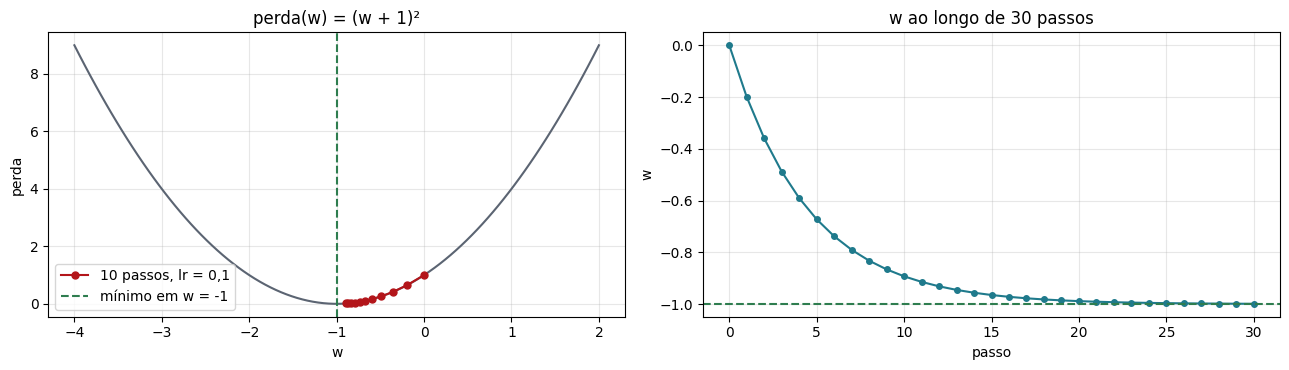

In [23]:
print("passo | w (laço) | w (fórmula -1 + 0,8^k)")
for k in [1, 5, 10]:
    print(f"{k:5d} | {caminho_ex1[k]:8.4f} | {-1 + 0.8 ** k:8.4f}")

for tolerancia in [0.01, 0.001]:
    k = int(np.ceil(np.log(tolerancia) / np.log(0.8)))
    print(f"\npara ficar a menos de {tolerancia} de w = -1 são necessários {k} passos")

caminho_longo = np.array([-1 + 0.8 ** k for k in range(31)])
w_graf = np.linspace(-4, 2, 100)

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
eixos[0].plot(w_graf, (w_graf + 1) ** 2, color=CINZA)
eixos[0].plot(caminho_ex1, (np.array(caminho_ex1) + 1) ** 2, "o-", color=VERMELHO, markersize=5, label="10 passos, lr = 0,1")
eixos[0].axvline(-1, color=VERDE, linestyle="--", label="mínimo em w = -1")
eixos[0].set_xlabel("w"); eixos[0].set_ylabel("perda"); eixos[0].set_title("perda(w) = (w + 1)²")
eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(caminho_longo, "o-", color=AZUL, markersize=4)
eixos[1].axhline(-1, color=VERDE, linestyle="--")
eixos[1].set_xlabel("passo"); eixos[1].set_ylabel("w"); eixos[1].set_title("w ao longo de 30 passos")
eixos[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretação — Exercício 1**

**O $w$ vai para $-1$, como previsto.** O gradiente em $w = 0$ é $+2$, então a descida anda para a **esquerda**, diminuindo $w$. No exemplo da aula o gradiente era negativo e o $w$ andava para a direita. A regra é a mesma nos dois casos: o sinal do gradiente diz para que lado a perda sobe, e o otimizador anda para o lado oposto.

- **A perda cai a cada passo**, de 1,0 no início para 0,018 no décimo passo.
- **Em 10 passos, o $w$ ainda não chegou.** Ele está em cerca de $-0{,}89$. Com `lr = 0.1`, a distância até o mínimo é multiplicada por 0,8 a cada passo. Os valores do laço batem exatamente com a fórmula $-1 + 0{,}8^k$.
- **Os passos ficam cada vez menores.** Perto do fundo, o gradiente $2(w+1)$ quase some, e o passo também. Por isso o $w$ se aproxima de $-1$ cada vez mais devagar e, em teoria, nunca chega exatamente. São necessários 21 passos para ficar a menos de 0,01 do mínimo e 31 para ficar a menos de 0,001.

Mudar o mínimo de lugar não muda nada no método. Só o ponto de chegada é diferente.

---
### Exercício 2 — SGD com `lr = 3.0`

> Na Seção 3, teste o SGD com `lr = 3.0`. O treino ainda funciona?

Treino a mesma rede da Seção 3 com `lr = 3.0` e comparo com `lr = 1.0`, o maior valor testado na aula.

lr = 1.0  | perda inicial = 2.307 | perda final = 0.055 | maior perda = 2.349 | acurácia no teste = 97.6%
lr = 3.0  | perda inicial = 2.307 | perda final = 2.302 | maior perda = 10.868 | acurácia no teste = 9.3%


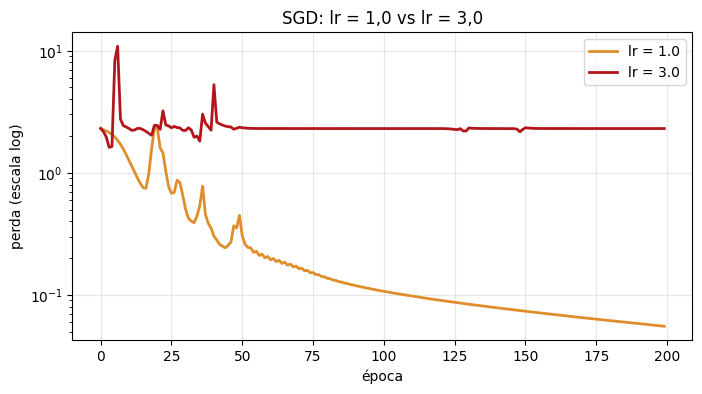

In [24]:
plt.figure(figsize=(8, 4))
for lr, cor in zip([1.0, 3.0], [LARANJA, VERMELHO]):
    torch.manual_seed(42)
    rede = criar_rede()
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=lr))
    print(f"lr = {lr:<4} | perda inicial = {historico[0]:.3f} | perda final = {historico[-1]:.3f} | "
          f"maior perda = {max(historico):.3f} | acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")
    plt.plot(historico, color=cor, linewidth=2, label=f"lr = {lr}")

plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda (escala log)")
plt.title("SGD: lr = 1,0 vs lr = 3,0"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Um único treino pode enganar. Repito com 5 sementes e testo uma faixa maior de taxas de aprendizado, para achar a partir de onde o SGD deixa de funcionar.

In [25]:
lrs_ex2 = [0.3, 1.0, 2.0, 3.0, 5.0, 10.0]
print(f"{'lr':>5} | " + " | ".join(f"sem. {s}" for s in range(5)) + " | média")
print("-" * 58)
for lr in lrs_ex2:
    accs = []
    for semente in range(5):
        torch.manual_seed(semente)
        rede = criar_rede()
        treinar(rede, torch.optim.SGD(rede.parameters(), lr=lr))
        accs.append(acuracia(rede, X_teste, Y_teste))
    print(f"{lr:>5} | " + " | ".join(f"{a:6.1%}" for a in accs) + f" | {np.mean(accs):5.1%}")

   lr | sem. 0 | sem. 1 | sem. 2 | sem. 3 | sem. 4 | média
----------------------------------------------------------


  0.3 |  95.2% |  96.1% |  95.4% |  95.0% |  95.7% | 95.5%


  1.0 |  97.4% |  97.6% |  97.4% |  97.6% |  97.4% | 97.5%


  2.0 |   9.3% |  18.1% |  21.1% |   9.3% |  95.0% | 30.6%


  3.0 |   9.3% |   9.3% |   9.3% |   9.3% |   9.3% |  9.3%


  5.0 |   9.3% |   9.3% |   9.3% |   9.3% |   9.3% |  9.3%


 10.0 |   9.3% |   9.3% |   9.3% |   9.3% |   9.3% |  9.3%


Para ver **como** o treino se comporta com `lr = 3.0`, olho as primeiras épocas de perto, junto com a acurácia no treino a cada época.

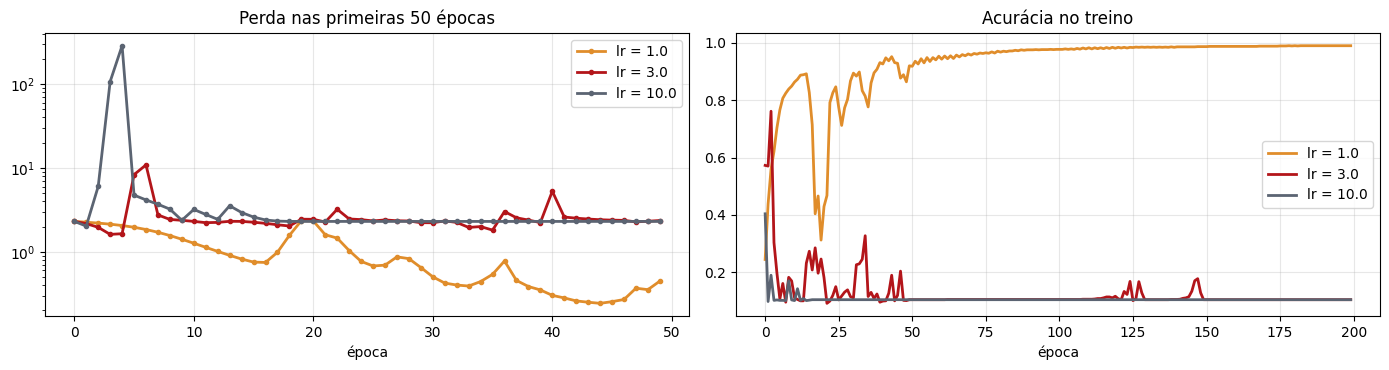

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 3.8))
for lr, cor in zip([1.0, 3.0, 10.0], [LARANJA, VERMELHO, CINZA]):
    torch.manual_seed(42)
    rede = criar_rede()
    otimizador = torch.optim.SGD(rede.parameters(), lr=lr)
    perda_fn = nn.CrossEntropyLoss()
    perdas, accs = [], []
    for epoca in range(200):
        perda = perda_fn(rede(X_treino), Y_treino)
        otimizador.zero_grad(); perda.backward(); otimizador.step()
        perdas.append(perda.item()); accs.append(acuracia(rede, X_treino, Y_treino))
    eixos[0].plot(perdas[:50], color=cor, linewidth=2, marker=".", label=f"lr = {lr}")
    eixos[1].plot(accs, color=cor, linewidth=2, label=f"lr = {lr}")

eixos[0].set_yscale("log"); eixos[0].set_title("Perda nas primeiras 50 épocas"); eixos[0].set_xlabel("época")
eixos[1].set_title("Acurácia no treino"); eixos[1].set_xlabel("época")
for e in eixos: e.legend(); e.grid(alpha=0.3)
plt.tight_layout(); plt.show()

A perda com `lr = 3.0` não explode para sempre: depois de alguns picos, ela fica parada em cerca de 2,302. Esse número é $\ln(10)$, a perda de quem dá probabilidade igual, 10%, para cada um dos 10 dígitos. Suspeito que os neurônios da camada oculta "morreram": a ReLU deles devolve zero para **todas** as imagens, então nenhum gradiente passa por eles e a rede fica travada. Confiro isso contando, depois do treino, quantos dos 64 neurônios ocultos ficam zerados em todos os exemplos de treino.

In [27]:
for lr in [1.0, 2.0, 3.0]:
    torch.manual_seed(42)
    rede = criar_rede()
    treinar(rede, torch.optim.SGD(rede.parameters(), lr=lr))
    with torch.no_grad():
        ocultos = rede[1](rede[0](X_treino))          # saída da ReLU, formato (1257, 64)
        mortos = (ocultos.max(dim=0).values == 0).sum().item()
        previsoes = rede(X_treino).argmax(dim=1)
    classes_previstas = torch.unique(previsoes).tolist()
    print(f"lr = {lr}: neurônios mortos = {mortos:2d} de 64 | classes que a rede prevê = {classes_previstas}")

lr = 1.0: neurônios mortos = 10 de 64 | classes que a rede prevê = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
lr = 2.0: neurônios mortos = 64 de 64 | classes que a rede prevê = [1]
lr = 3.0: neurônios mortos = 64 de 64 | classes que a rede prevê = [1]


**Interpretação — Exercício 2**

**Não, com `lr = 3.0` o treino não funciona.** A acurácia no teste fica em 9,3% em todas as 5 sementes. É o mesmo que chutar um dígito, já que há 10 classes.

- **Os passos são grandes demais.** Nas primeiras épocas, a perda dá saltos e chega perto de 11, como o $w$ que "pula por cima do vale" no exemplo da Seção 1.
- **Depois dos saltos, a rede morre.** A perda se estabiliza em cerca de 2,302, que é $\ln(10)$. Um passo grande empurra os pesos para valores em que a ReLU de **todos os 64 neurônios** ocultos devolve zero para qualquer imagem. Sem nenhum neurônio ativo, a saída é sempre a mesma, e a rede passa a prever o dígito 1 para todas as imagens. Como a derivada da ReLU é zero nesse trecho, nenhum gradiente volta para a primeira camada, e a rede não consegue mais se recuperar. É o problema dos **neurônios mortos**.
- **O limite está entre 1 e 2.** Com `lr = 1.0`, o treino ainda funciona muito bem: 97,5% em média, mesmo com alguns picos na perda e 10 neurônios mortos. Com `lr = 2.0`, o resultado vira loteria: uma semente chegou a 95%, as outras ficaram entre 9% e 21%. A partir de 3, o treino falha sempre.

**Conclusão:** aumentar o `lr` acelera o treino só até certo ponto. Passando do limite, o treino fica instável e pode quebrar de vez. Aqui, o maior `lr` que funciona com segurança, 1,0, está muito perto de um que já não funciona.

---
### Exercício 3 — Lote completo por 300 épocas

> Na Seção 5, treine com lote completo por **300** épocas em vez de 30. Ele alcança os lotes pequenos?

Uso a função `treinar_em_lotes` da Seção 5, com o lote completo e 300 épocas. Como referência, treino também os lotes de 8, 32 e 128 por 30 épocas, como na aula. Meço também o tempo de cada treino.

In [28]:
import time

resultados_ex3 = {}
for tamanho, epocas in [(8, 30), (32, 30), (128, 30), (len(X_treino), 30), (len(X_treino), 300)]:
    torch.manual_seed(42)
    rede = criar_rede()
    inicio = time.time()
    accs = treinar_em_lotes(rede, tamanho, epocas=epocas)
    duracao = time.time() - inicio
    passos_por_epoca = len(DataLoader(dados_treino, batch_size=tamanho))
    nome = f"lote = {tamanho}, {epocas} épocas"
    resultados_ex3[nome] = dict(accs=accs, passos_por_epoca=passos_por_epoca, tempo=duracao, tamanho=tamanho)
    print(f"{nome:<26} | passos no total = {passos_por_epoca * epocas:5d} | tempo = {duracao:5.2f} s | "
          f"acurácia final = {accs[-1]:.1%} | melhor = {max(accs):.1%}")

lote = 8, 30 épocas        | passos no total =  4740 | tempo =  2.05 s | acurácia final = 96.7% | melhor = 97.0%


lote = 32, 30 épocas       | passos no total =  1200 | tempo =  0.58 s | acurácia final = 95.9% | melhor = 96.1%


lote = 128, 30 épocas      | passos no total =   300 | tempo =  0.22 s | acurácia final = 93.7% | melhor = 93.7%
lote = 1257, 30 épocas     | passos no total =    30 | tempo =  0.13 s | acurácia final = 68.3% | melhor = 68.3%


lote = 1257, 300 épocas    | passos no total =   300 | tempo =  1.78 s | acurácia final = 95.9% | melhor = 95.9%


Desenho a acurácia no teste de duas formas: em função das **épocas** e em função do número de **passos** do otimizador (ou seja, de quantas vezes `otimizador.step()` foi chamado).

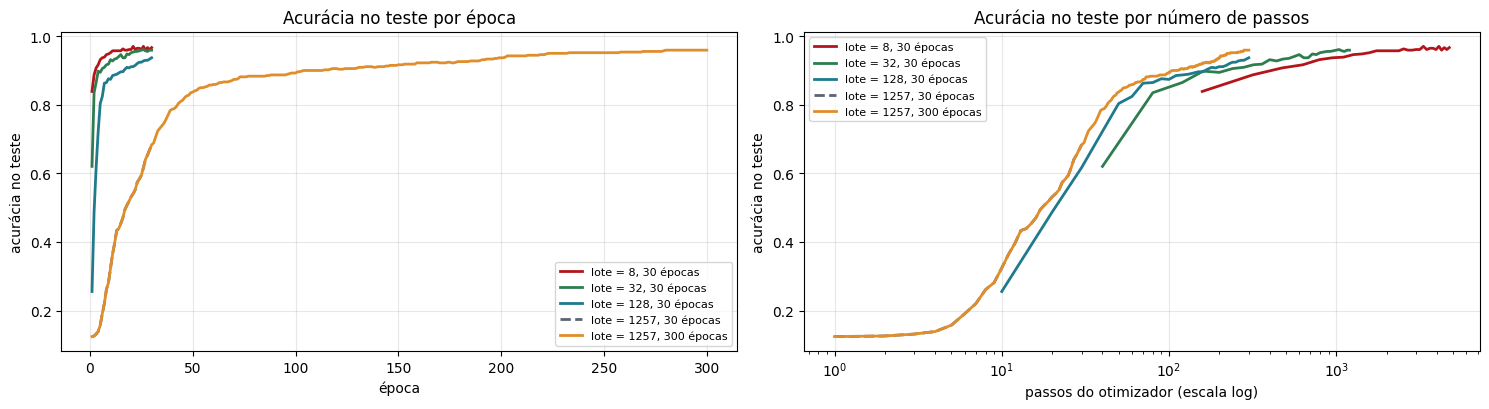

In [29]:
cores_ex3 = [VERMELHO, VERDE, AZUL, CINZA, LARANJA]
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.2))
for (nome, r), cor in zip(resultados_ex3.items(), cores_ex3):
    epocas_x = np.arange(1, len(r["accs"]) + 1)
    estilo = "--" if "30 épocas" in nome and r["tamanho"] == len(X_treino) else "-"
    eixos[0].plot(epocas_x, r["accs"], color=cor, linewidth=2, linestyle=estilo, label=nome)
    eixos[1].plot(epocas_x * r["passos_por_epoca"], r["accs"], color=cor, linewidth=2, linestyle=estilo, label=nome)

eixos[0].set_xlabel("época"); eixos[0].set_title("Acurácia no teste por época")
eixos[1].set_xlabel("passos do otimizador (escala log)"); eixos[1].set_xscale("log")
eixos[1].set_title("Acurácia no teste por número de passos")
for e in eixos: e.set_ylabel("acurácia no teste"); e.legend(fontsize=8); e.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Em quantas épocas o lote completo chega à acurácia que os lotes pequenos alcançam em 30 épocas?

In [30]:
accs_completo = np.array(resultados_ex3[f"lote = {len(X_treino)}, 300 épocas"]["accs"])
for nome in ["lote = 8, 30 épocas", "lote = 32, 30 épocas", "lote = 128, 30 épocas"]:
    alvo = resultados_ex3[nome]["accs"][-1]
    atingiu = np.nonzero(accs_completo >= alvo)[0]
    quando = f"na época {atingiu[0] + 1}" if len(atingiu) else "não atinge em 300 épocas"
    print(f"{nome:<22} termina com {alvo:.1%} -> lote completo atinge esse valor {quando}")

lote = 8, 30 épocas    termina com 96.7% -> lote completo atinge esse valor não atinge em 300 épocas
lote = 32, 30 épocas   termina com 95.9% -> lote completo atinge esse valor na época 280
lote = 128, 30 épocas  termina com 93.7% -> lote completo atinge esse valor na época 199


**Interpretação — Exercício 3**

**Quase.** Com 300 épocas, o lote completo chega a 95,9% no teste. Isso empata com o lote de 32 em 30 épocas e supera o lote de 128, que chegou a 93,7%. Mas ainda fica abaixo do lote de 8, com 96,7%. No gráfico, a linha tracejada do lote completo com 30 épocas fica escondida sob a laranja, porque as 30 primeiras épocas dos dois treinos são idênticas.

O custo, porém, é muito maior: o lote completo precisa de **10 vezes mais épocas** para chegar onde o lote de 32 chega. Ele só alcança o lote de 32 perto da época 280, e o de 128 na época 199.

**O que realmente importa é o número de passos.** O gráfico da direita conta quantas vezes o otimizador corrigiu os pesos:

- **Com o mesmo número de passos, o lote completo vai até melhor.** O lote de 128 em 30 épocas e o lote completo em 300 épocas dão os mesmos 300 passos. O lote completo termina com 95,9%, contra 93,7%. Cada passo dele usa o gradiente exato, calculado com todos os dados.
- **Com o mesmo número de épocas, os lotes pequenos ganham.** Numa época, o lote de 8 dá 158 passos, e o lote completo dá só 1. Cada passo dos lotes pequenos é mais "barulhento", mas eles dão muitos mais passos por passada pelos dados.
- **O tempo conta outra história.** O lote completo levou cerca de 1,8 segundo para 300 épocas. O lote de 32 levou 0,6 segundo para chegar à mesma acurácia. O lote de 8 levou 2 segundos: ele dá muitos passos, mas cada um aproveita mal o processamento em paralelo.

**Conclusão:** o lote completo até alcança os lotes médios, mas gasta muito mais épocas e mais tempo para isso. Lotes de tamanho intermediário, como 32, são o melhor equilíbrio entre passos por época e custo de cada passo. Isso confirma a regra prática da aula.

---
### Exercício 4 — Seção 6 com `lr = 0.001`

> Na Seção 6, troque o `lr` para `0.001`. Quantas épocas são necessárias para a acurácia de teste passar de 90%?

Repito o experimento da Seção 6 (Adam, lote completo, mesma semente) com `lr = 0.001`. Como não sei de antemão quantas épocas serão necessárias, treino por 1500 épocas e procuro a primeira época em que o teste passa de 90%. Para comparar, faço o mesmo com o `lr = 0.01` da aula.

In [31]:
def secao6(lr, epocas):
    torch.manual_seed(42)
    rede = criar_rede()
    otimizador = torch.optim.Adam(rede.parameters(), lr=lr)
    perda_fn = nn.CrossEntropyLoss()
    acc_tr, acc_te = [], []
    for epoca in range(epocas):
        perda = perda_fn(rede(X_treino), Y_treino)
        otimizador.zero_grad(); perda.backward(); otimizador.step()
        acc_tr.append(acuracia(rede, X_treino, Y_treino))
        acc_te.append(acuracia(rede, X_teste, Y_teste))
    return np.array(acc_tr), np.array(acc_te)


def primeira_epoca(accs, limiar):
    idx = np.nonzero(accs > limiar)[0]
    return idx[0] + 1 if len(idx) else None      # +1: a época 1 é a primeira


EPOCAS_EX4 = 1500
curvas_ex4 = {lr: secao6(lr, EPOCAS_EX4) for lr in [0.01, 0.001]}

for lr, (acc_tr, acc_te) in curvas_ex4.items():
    print(f"lr = {lr}:")
    for limiar in [0.5, 0.8, 0.9, 0.95]:
        print(f"   teste passa de {limiar:.0%} na época {primeira_epoca(acc_te, limiar)}")
    print(f"   treino chega a 100% na época {primeira_epoca(acc_tr, 0.9999)}")
    print(f"   acurácia no teste: época 300 = {acc_te[299]:.1%} | época {EPOCAS_EX4} = {acc_te[-1]:.1%} | melhor = {acc_te.max():.1%}\n")

lr = 0.01:
   teste passa de 50% na época 2
   teste passa de 80% na época 7
   teste passa de 90% na época 17
   teste passa de 95% na época 39
   treino chega a 100% na época 148
   acurácia no teste: época 300 = 97.6% | época 1500 = 97.8% | melhor = 97.8%

lr = 0.001:
   teste passa de 50% na época 18
   teste passa de 80% na época 43
   teste passa de 90% na época 114
   teste passa de 95% na época 233
   treino chega a 100% na época 1057
   acurácia no teste: época 300 = 95.9% | época 1500 = 98.0% | melhor = 98.0%



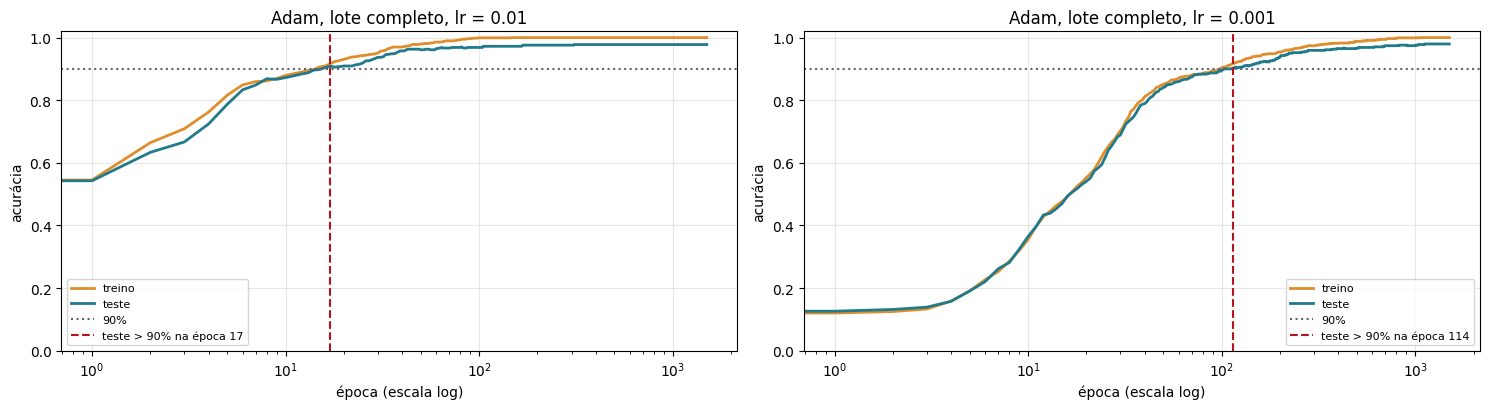

In [32]:
ep90 = primeira_epoca(curvas_ex4[0.001][1], 0.9)

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.2))
for eixo, lr in zip(eixos, [0.01, 0.001]):
    acc_tr, acc_te = curvas_ex4[lr]
    eixo.plot(acc_tr, color=LARANJA, linewidth=2, label="treino")
    eixo.plot(acc_te, color=AZUL, linewidth=2, label="teste")
    eixo.axhline(0.9, color=CINZA, linestyle=":", label="90%")
    e90 = primeira_epoca(acc_te, 0.9)
    eixo.axvline(e90, color=VERMELHO, linestyle="--", label=f"teste > 90% na época {e90}")
    eixo.set_xscale("log"); eixo.set_ylim(0, 1.02)
    eixo.set_xlabel("época (escala log)"); eixo.set_ylabel("acurácia"); eixo.set_title(f"Adam, lote completo, lr = {lr}")
    eixo.legend(fontsize=8); eixo.grid(alpha=0.3)
plt.tight_layout(); plt.show()

O resultado pode depender da semente. Repito o cálculo da época em que o teste passa de 90% para 5 sementes.

In [33]:
def epoca_90(lr, semente, max_epocas=1500):
    torch.manual_seed(semente)
    rede = criar_rede()
    otimizador = torch.optim.Adam(rede.parameters(), lr=lr)
    perda_fn = nn.CrossEntropyLoss()
    for epoca in range(max_epocas):
        perda = perda_fn(rede(X_treino), Y_treino)
        otimizador.zero_grad(); perda.backward(); otimizador.step()
        if acuracia(rede, X_teste, Y_teste) > 0.9:
            return epoca + 1
    return None

for lr in [0.01, 0.001]:
    epocas_90 = [epoca_90(lr, s) for s in range(5)]
    print(f"lr = {lr:<5}: épocas até o teste passar de 90% = {epocas_90} | média = {np.mean(epocas_90):.0f}")

lr = 0.01 : épocas até o teste passar de 90% = [18, 17, 19, 19, 22] | média = 19


lr = 0.001: épocas até o teste passar de 90% = [101, 117, 105, 109, 114] | média = 109


**Interpretação — Exercício 4**

**Com `lr = 0.001`, o teste passa de 90% na época 114.** Com o `lr = 0.01` da aula, isso acontece na época 17, cerca de 7 vezes antes. Repetindo com 5 sementes, a resposta fica entre 101 e 117 épocas, com média de 109. Com `lr = 0.01`, a média é de 19 épocas. A conclusão não depende da semente.

- **Um `lr` 10 vezes menor deixa o treino bem mais lento.** Todas as marcas demoram mais: 50% de acurácia na época 18 em vez da 2, e 95% na época 233 em vez da 39. Nas 300 épocas da aula, a rede ainda estaria em 95,9%, contra 97,6% com `lr = 0.01`.
- **A desaceleração não é exatamente de 10 vezes.** O Adam ajusta o tamanho dos passos por conta própria, então reduzir o `lr` em 10 vezes não multiplica o tempo exatamente por 10.
- **No fim, os dois chegam ao mesmo lugar.** Depois de 1500 épocas, `lr = 0.001` termina com 98,0% no teste, contra 97,8% com `lr = 0.01`. A diferença é de uns poucos acertos, dentro da variação entre sementes. O `lr` menor não leva a um resultado pior, só demora mais.
- **O sobreajuste também chega mais tarde.** Com `lr = 0.001`, o treino só chega a 100% na época 1057, e não na 148. Enquanto isso, o teste continua subindo devagar.

**Conclusão:** um `lr` pequeno não estraga o treino, mas exige muitas mais épocas. Esse é o lado oposto do Exercício 2, em que um `lr` grande demais quebrava o treino.

---
### Exercício 5 — Inicializações com desvio 0,1 e 0,3

> Na Seção 7, crie um modo de inicialização com desvio **0,1** e outro com **0,3**. Algum deles faz a rede de 10 camadas treinar?

**Previsão antes de executar.** Numa camada `Linear(64, 64)` seguida de ReLU, com pesos de desvio $\sigma$, o tamanho do sinal é multiplicado aproximadamente por $\sigma\sqrt{64/2} = \sigma\sqrt{32} \approx 5{,}66\,\sigma$ a cada camada. O fator 1/2 aparece porque a ReLU zera cerca de metade dos valores.

| desvio | fator por camada | fator após 10 camadas |
|---|---|---|
| 0,01 ("pequena") | 0,057 | praticamente zero |
| 0,1 | 0,57 | cerca de 0,004 (encolhe) |
| 0,177 (He) | 1,00 | 1 (estável) |
| 0,3 | 1,70 | cerca de 200 (cresce) |
| 1,0 ("grande") | 5,66 | cerca de 300 milhões |

A inicialização de He escolhe exatamente o desvio que deixa esse fator igual a 1. Espero então que 0,1 faça o sinal encolher e 0,3 faça o sinal crescer, mas bem menos que nos casos extremos da aula.

Crio uma nova função de inicialização que aceita qualquer desvio, além dos modos da aula.

pequena (0,01)  | sinal na camada 1 = 0.0235 | na camada 10 = 8.55e-14 | fator médio por camada = 0.05
desvio 0,1      | sinal na camada 1 = 0.235 | na camada 10 = 0.000855 | fator médio por camada = 0.54
He (≈0,18)      | sinal na camada 1 = 0.416 | na camada 10 = 0.255 | fator médio por camada = 0.95
desvio 0,3      | sinal na camada 1 = 0.706 | na camada 10 = 50.5 | fator médio por camada = 1.61
grande (1,0)    | sinal na camada 1 = 2.35 | na camada 10 = 8.55e+06 | fator médio por camada = 5.36


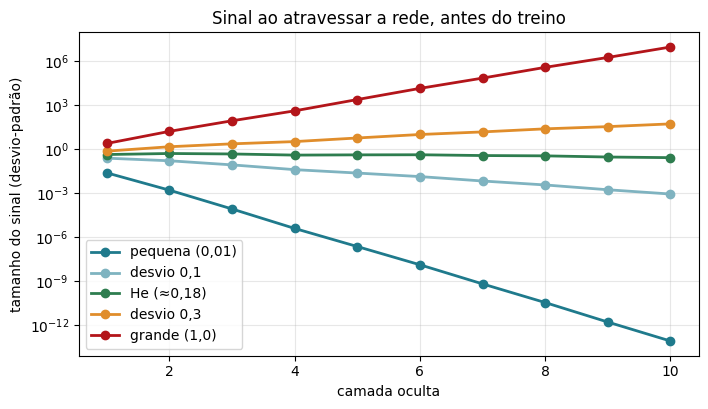

In [34]:
def inicializar_v2(rede, modo):
    # aceita os modos da aula e também um número: o desvio-padrão dos pesos
    if not isinstance(modo, (int, float)):
        return inicializar(rede, modo)
    for camada in rede:
        if isinstance(camada, nn.Linear):
            nn.init.normal_(camada.weight, mean=0.0, std=modo)
            nn.init.zeros_(camada.bias)
    return rede


def tamanhos_sinal(rede):
    tamanhos, h = [], X_treino
    with torch.no_grad():
        for camada in rede:
            h = camada(h)
            if isinstance(camada, nn.ReLU):
                tamanhos.append(h.std().item())
    return tamanhos


modos_ex5 = ["pequena", 0.1, "He", 0.3, "grande"]
cores_ex5 = {"pequena": AZUL, 0.1: "#7FB3C0", "He": VERDE, 0.3: LARANJA, "grande": VERMELHO}
nomes_ex5 = {"pequena": "pequena (0,01)", 0.1: "desvio 0,1", "He": "He (≈0,18)", 0.3: "desvio 0,3", "grande": "grande (1,0)"}

plt.figure(figsize=(8, 4.2))
for modo in modos_ex5:
    torch.manual_seed(42)
    t = tamanhos_sinal(inicializar_v2(criar_rede_profunda(), modo))
    plt.plot(range(1, 11), t, "o-", color=cores_ex5[modo], linewidth=2, label=nomes_ex5[modo])
    print(f"{nomes_ex5[modo]:<15} | sinal na camada 1 = {t[0]:.3g} | na camada 10 = {t[-1]:.3g} | "
          f"fator médio por camada = {(t[-1] / t[0]) ** (1 / 9):.2f}")
plt.yscale("log"); plt.xlabel("camada oculta"); plt.ylabel("tamanho do sinal (desvio-padrão)")
plt.title("Sinal ao atravessar a rede, antes do treino"); plt.legend(); plt.grid(alpha=0.3); plt.show()

O gradiente percorre a rede de trás para frente e sofre o mesmo efeito. Antes de treinar, calculo o tamanho do gradiente dos pesos de cada camada `Linear`.

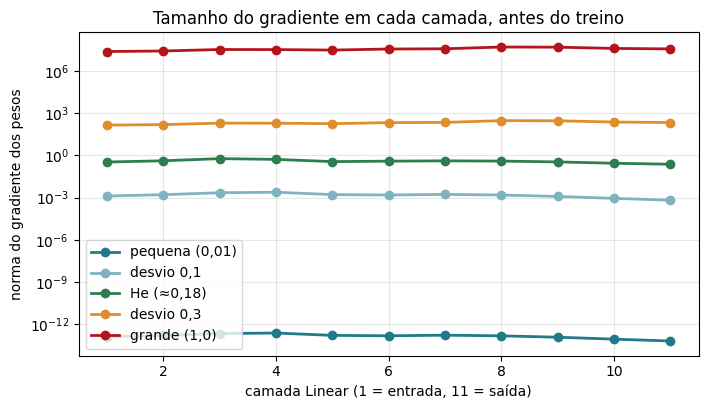

In [35]:
def tamanhos_gradiente(rede):
    rede.zero_grad()
    nn.CrossEntropyLoss()(rede(X_treino), Y_treino).backward()
    return [camada.weight.grad.norm().item() for camada in rede if isinstance(camada, nn.Linear)]

plt.figure(figsize=(8, 4.2))
for modo in modos_ex5:
    torch.manual_seed(42)
    g = tamanhos_gradiente(inicializar_v2(criar_rede_profunda(), modo))
    plt.plot(range(1, 12), g, "o-", color=cores_ex5[modo], linewidth=2, label=nomes_ex5[modo])
plt.yscale("log"); plt.xlabel("camada Linear (1 = entrada, 11 = saída)"); plt.ylabel("norma do gradiente dos pesos")
plt.title("Tamanho do gradiente em cada camada, antes do treino"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Agora treino as cinco versões exatamente como na Seção 7: SGD com `lr = 0.1` e 200 épocas.

pequena (0,01)  | perda inicial = 2.303 | perda final = 2.302 | acurácia no teste = 9.3%


desvio 0,1      | perda inicial = 2.302 | perda final = 2.293 | acurácia no teste = 10.0%


He (≈0,18)      | perda inicial = 2.287 | perda final = 0.4154 | acurácia no teste = 84.6%


desvio 0,3      | perda inicial = 129.8 | perda final = nan | acurácia no teste = 9.8%


grande (1,0)    | perda inicial = 7.327e+07 | perda final = nan | acurácia no teste = 9.8%


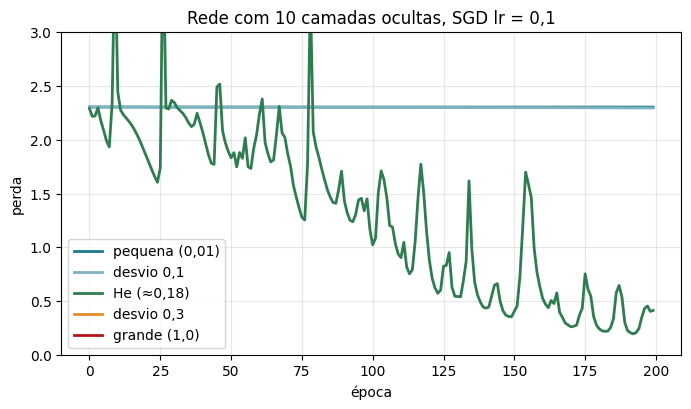

In [36]:
import warnings
warnings.filterwarnings("ignore")

plt.figure(figsize=(8, 4.2))
for modo in modos_ex5:
    torch.manual_seed(42)
    rede = inicializar_v2(criar_rede_profunda(), modo)
    historico = treinar(rede, torch.optim.SGD(rede.parameters(), lr=0.1))
    plt.plot(historico, color=cores_ex5[modo], linewidth=2, label=nomes_ex5[modo])
    print(f"{nomes_ex5[modo]:<15} | perda inicial = {historico[0]:.4g} | perda final = {historico[-1]:.4g} | "
          f"acurácia no teste = {acuracia(rede, X_teste, Y_teste):.1%}")
plt.ylim(0, 3); plt.xlabel("época"); plt.ylabel("perda")
plt.title("Rede com 10 camadas ocultas, SGD lr = 0,1"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Para não depender de uma única semente, repito o treino com 5 sementes e testo vários desvios entre 0,05 e 0,5. Assim vejo a **faixa** de desvios que funciona.

 desvio | sem. 0 | sem. 1 | sem. 2 | sem. 3 | sem. 4 | média
--------------------------------------------------------------


   0.05 |   9.3% |   9.3% |   9.3% |   9.3% |   9.3% |  9.3%


    0.1 |  14.6% |  15.4% |   9.8% |   9.3% |  10.9% | 12.0%


   0.13 |  71.3% |  43.0% |  41.1% |  83.5% |  44.1% | 56.6%


   0.15 |  94.3% |  86.9% |  88.7% |  66.7% |  84.1% | 84.1%


  0.177 |  92.6% |  93.1% |  94.8% |  96.1% |  96.1% | 94.6%


    0.2 |  94.6% |  95.9% |  96.9% |  80.9% |  84.3% | 90.5%


   0.25 |   9.8% |   9.8% |   9.8% |   9.8% |   9.8% |  9.8%


    0.3 |   9.8% |   9.8% |   9.8% |   9.8% |   9.8% |  9.8%


    0.4 |   9.8% |   9.8% |   9.8% |   9.8% |   9.8% |  9.8%


    0.5 |   9.8% |   9.8% |   9.8% |   9.8% |   9.8% |  9.8%


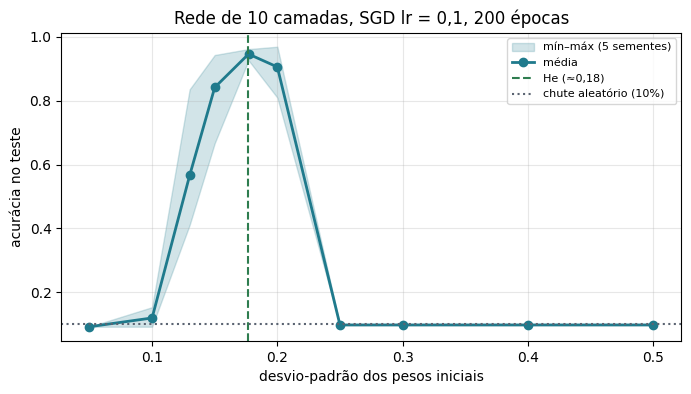

In [37]:
desvios = [0.05, 0.1, 0.13, 0.15, 0.177, 0.2, 0.25, 0.3, 0.4, 0.5]
media_acc, min_acc, max_acc = [], [], []
print(f"{'desvio':>7} | " + " | ".join(f"sem. {s}" for s in range(5)) + " | média")
print("-" * 62)
for desvio in desvios:
    accs = []
    for semente in range(5):
        torch.manual_seed(semente)
        rede = inicializar_v2(criar_rede_profunda(), desvio)
        treinar(rede, torch.optim.SGD(rede.parameters(), lr=0.1))
        accs.append(acuracia(rede, X_teste, Y_teste))
    media_acc.append(np.mean(accs)); min_acc.append(min(accs)); max_acc.append(max(accs))
    print(f"{desvio:>7} | " + " | ".join(f"{a:6.1%}" for a in accs) + f" | {np.mean(accs):5.1%}")

plt.figure(figsize=(8, 4))
plt.fill_between(desvios, min_acc, max_acc, color=AZUL, alpha=0.2, label="mín–máx (5 sementes)")
plt.plot(desvios, media_acc, "o-", color=AZUL, linewidth=2, label="média")
plt.axvline(np.sqrt(2 / 64), color=VERDE, linestyle="--", label="He (≈0,18)")
plt.axhline(0.1, color=CINZA, linestyle=":", label="chute aleatório (10%)")
plt.xlabel("desvio-padrão dos pesos iniciais"); plt.ylabel("acurácia no teste")
plt.title("Rede de 10 camadas, SGD lr = 0,1, 200 épocas"); plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

**Interpretação — Exercício 5**

**Nenhum dos dois faz a rede treinar com o SGD.** Com desvio 0,1, a acurácia fica em 10%. Com desvio 0,3, a perda vira `nan`. Os dois falham, mas por motivos **opostos**, exatamente como as inicializações "pequena" e "grande" da aula.

- **Com desvio 0,1, o sinal some.** O sinal encolhe para cerca de 54% a cada camada, perto do 0,57 previsto. Depois de 10 camadas, ele fica quase 300 vezes menor que na primeira. O gradiente também fica centenas de vezes menor que com He. Com passos tão pequenos, a perda fica praticamente parada em 2,30 e a rede não aprende nada em 200 épocas.
- **Com desvio 0,3, o sinal explode.** O sinal cresce cerca de 1,6 vez por camada, perto do 1,70 previsto, e chega a ficar 70 vezes maior na última camada. A perda inicial já é cerca de 130, contra 2,3 nos outros casos. O gradiente é centenas de vezes maior que com He. Com `lr = 0.1`, o primeiro passo é enorme, os pesos disparam e a perda vira `nan`.
- **A faixa que funciona é estreita.** Testando vários desvios com 5 sementes, a rede só treina bem entre cerca de 0,15 e 0,2. É uma faixa estreita em torno do valor de He, 0,177, que deu a melhor média, 94,6%. Abaixo de 0,13, a rede não aprende. A partir de 0,25, o treino sempre explode.
- **A profundidade amplia qualquer erro na escala.** Um erro no desvio vira um fator que se repete a cada camada. Um fator de 0,54 ou de 1,6 parece pouco, mas elevado à décima potência vira 0,004 ou 70. Por isso, numa rede rasa quase qualquer inicialização funciona, e numa rede profunda não.

**Conclusão:** a inicialização de He não é um valor mágico. É o desvio calculado para manter o sinal do mesmo tamanho em todas as camadas. Errar para menos faz o sinal sumir, e errar para mais faz o sinal explodir. Em ambos os casos, a rede deixa de treinar.

---
### Exercício 6 — Trocando o SGD pelo Adam

> Repita o treino da Seção 7 trocando o SGD pelo Adam (`lr=0.001`). Quais inicializações passam a funcionar? O Adam resolve tudo?

Treino a rede de 10 camadas com as quatro inicializações da aula e as duas novas do Exercício 5, agora com Adam e `lr = 0.001`, por 200 épocas.

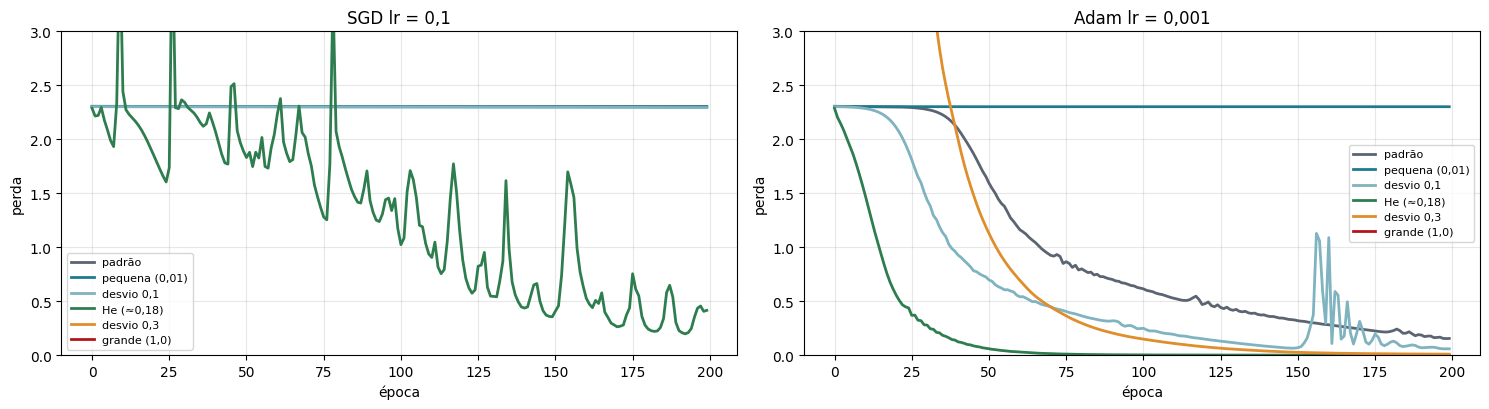

inicialização   | SGD teste | Adam treino | Adam teste | perda final Adam
----------------------------------------------------------------------------
padrão          |      9.3% |       94.9% |      88.7% | 0.1551
pequena (0,01)  |      9.3% |       10.5% |       9.3% | 2.302
desvio 0,1      |     10.0% |       98.6% |      92.6% | 0.05939
He (≈0,18)      |     84.6% |      100.0% |      95.0% | 0.0004846
desvio 0,3      |      9.8% |      100.0% |      73.3% | 0.00981
grande (1,0)    |      9.8% |       93.4% |      63.9% | 1.688e+05


In [38]:
modos_ex6 = ["padrão", "pequena", 0.1, "He", 0.3, "grande"]
cores_ex5["padrão"] = CINZA; nomes_ex5["padrão"] = "padrão"

fig, eixos = plt.subplots(1, 2, figsize=(15, 4.2))
hist_ex6 = {}
for modo in modos_ex6:
    for eixo, (nome_ot, criar_ot) in zip(eixos, [("SGD lr = 0,1", lambda p: torch.optim.SGD(p, lr=0.1)),
                                                 ("Adam lr = 0,001", lambda p: torch.optim.Adam(p, lr=0.001))]):
        torch.manual_seed(42)
        rede = inicializar_v2(criar_rede_profunda(), modo)
        historico = treinar(rede, criar_ot(rede.parameters()))
        hist_ex6[(modo, nome_ot)] = (historico, acuracia(rede, X_teste, Y_teste), acuracia(rede, X_treino, Y_treino))
        eixo.plot(historico, color=cores_ex5[modo], linewidth=2, label=nomes_ex5[modo])
        eixo.set_title(nome_ot)

for e in eixos:
    e.set_ylim(0, 3); e.set_xlabel("época"); e.set_ylabel("perda"); e.legend(fontsize=8); e.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'inicialização':<15} | {'SGD teste':>9} | {'Adam treino':>11} | {'Adam teste':>10} | perda final Adam")
print("-" * 76)
for modo in modos_ex6:
    _, acc_sgd, _ = hist_ex6[(modo, "SGD lr = 0,1")]
    h_adam, acc_adam, acc_adam_tr = hist_ex6[(modo, "Adam lr = 0,001")]
    print(f"{nomes_ex5[modo]:<15} | {acc_sgd:>9.1%} | {acc_adam_tr:>11.1%} | {acc_adam:>10.1%} | {h_adam[-1]:.4g}")

Repito o treino com Adam para 5 sementes, para confirmar quais inicializações funcionam de forma consistente.

In [39]:
print(f"{'inicialização':<15} | " + " | ".join(f"sem. {s}" for s in range(5)) + " | média")
print("-" * 70)
for modo in modos_ex6:
    accs = []
    for semente in range(5):
        torch.manual_seed(semente)
        rede = inicializar_v2(criar_rede_profunda(), modo)
        treinar(rede, torch.optim.Adam(rede.parameters(), lr=0.001))
        accs.append(acuracia(rede, X_teste, Y_teste))
    print(f"{nomes_ex5[modo]:<15} | " + " | ".join(f"{a:6.1%}" for a in accs) + f" | {np.mean(accs):5.1%}")

inicialização   | sem. 0 | sem. 1 | sem. 2 | sem. 3 | sem. 4 | média
----------------------------------------------------------------------


padrão          |  89.4% |  90.6% |  85.4% |  66.9% |  69.3% | 80.3%


pequena (0,01)  |   9.3% |   9.3% |   9.3% |   9.3% |   9.3% |  9.3%


desvio 0,1      |  92.2% |  92.0% |  91.7% |  96.1% |  94.3% | 93.3%


He (≈0,18)      |  97.0% |  97.0% |  96.7% |  96.1% |  96.1% | 96.6%


desvio 0,3      |  68.0% |  65.9% |  67.0% |  73.9% |  65.0% | 68.0%


grande (1,0)    |  63.9% |  56.7% |  63.9% |  64.8% |  62.4% | 62.3%


**Por que o Adam ajuda com pesos pequenos?** O SGD dá passos proporcionais ao gradiente: se o gradiente é minúsculo, o passo também é. O Adam divide cada gradiente pela sua própria média de tamanho, então o passo de cada peso fica perto de `lr`, por menor que seja o gradiente. Confiro isso medindo, no primeiro passo de treino, quanto os pesos da primeira camada mudam com cada otimizador.

In [40]:
print(f"{'inicialização':<15} | {'gradiente camada 1':>18} | {'mudança SGD':>12} | {'mudança Adam':>12}")
print("-" * 68)
for modo in ["pequena", "He", "grande"]:
    mudancas = []
    for criar_ot in [lambda p: torch.optim.SGD(p, lr=0.1), lambda p: torch.optim.Adam(p, lr=0.001)]:
        torch.manual_seed(42)
        rede = inicializar_v2(criar_rede_profunda(), modo)
        otimizador = criar_ot(rede.parameters())
        antes = rede[0].weight.detach().clone()
        perda = nn.CrossEntropyLoss()(rede(X_treino), Y_treino)
        otimizador.zero_grad(); perda.backward()
        grad = rede[0].weight.grad.abs().mean().item()
        otimizador.step()
        mudancas.append((rede[0].weight.detach() - antes).abs().mean().item())
    print(f"{nomes_ex5[modo]:<15} | {grad:>18.3g} | {mudancas[0]:>12.3g} | {mudancas[1]:>12.3g}")

inicialização   | gradiente camada 1 |  mudança SGD | mudança Adam
--------------------------------------------------------------------
pequena (0,01)  |           1.15e-15 |            0 |     7.19e-11
He (≈0,18)      |              0.003 |       0.0003 |     0.000892
grande (1,0)    |           1.82e+05 |     1.82e+04 |      0.00089


**Interpretação — Exercício 6**

**Com o Adam, quase todas as inicializações passam a treinar alguma coisa: só a "pequena" continua travada.** Mas "treinar" não quer dizer "funcionar bem". O Adam não resolve tudo.

| inicialização | SGD | Adam, média de 5 sementes |
|---|---|---|
| padrão | não treina | 80% (de 67% a 91%) |
| pequena (0,01) | não treina | não treina |
| desvio 0,1 | não treina | 93% |
| He | 85% | 97% |
| desvio 0,3 | explode | 68% |
| grande (1,0) | explode | 62% |

**Por que o Adam ajuda?** O SGD dá passos proporcionais ao gradiente, enquanto o Adam divide cada gradiente pelo seu próprio tamanho típico. Assim, cada peso anda cerca de `lr` por passo, seja o gradiente minúsculo ou enorme. A última tabela mostra isso. Com He e com pesos grandes, o Adam muda os pesos da primeira camada praticamente na mesma quantidade, perto de 0,0009. Já o SGD muda cerca de 0,0003 com He e cerca de 18 mil com pesos grandes, o que destrói a rede.

**Por que ele não resolve tudo?**

- **Pesos pequenos demais continuam travados.** O gradiente fica na casa de $10^{-15}$. O Adam soma um número fixo e minúsculo ao denominador, o `eps`, igual a $10^{-8}$, para nunca dividir por zero. Com um gradiente ainda menor que esse `eps`, a divisão não "amplifica" mais nada, e o passo fica perto de $10^{-10}$. Na prática, a rede continua parada.
- **Pesos grandes treinam, mas generalizam mal.** Com desvio 0,3, a rede chega a 100% no treino e só 73% no teste. Com pesos grandes, a perda final ainda é enorme, mais de 100 mil, e o teste fica em 64%. O Adam evita a explosão, mas parte de uma rede que reage de forma exagerada a pequenas mudanças na imagem. Ela até consegue decorar o treino, mas não aprende um padrão que valha para imagens novas.
- **A inicialização padrão fica instável.** A média é de 80%, mas varia de 67% a 91% conforme a semente. A rede começa com um sinal fraco e demora para "pegar".
- **He continua sendo a melhor.** Com Adam, ela é a mais rápida, a mais estável entre sementes e a de maior acurácia no teste.

**Conclusão:** o Adam deixa o treino muito mais tolerante a uma escala ruim dos pesos, porque corrige o tamanho dos passos. Ele não corrige o ponto de partida. Uma boa inicialização continua sendo necessária, e as duas ajudas se somam: com Adam **e** He, a rede de 10 camadas chega a cerca de 97%.

---
### Conclusões gerais

1. **O gradiente indica a direção, e o `lr` indica o tamanho do passo.** O método é sempre o mesmo, qualquer que seja o mínimo, como mostrou o Exercício 1.
2. **O `lr` tem uma faixa útil.** Pequeno demais, o treino é lento: no Exercício 4, foram necessárias cerca de 7 vezes mais épocas. Grande demais, o treino quebra: no Exercício 2, todos os neurônios morreram.
3. **O que importa é o número de passos, não o de épocas.** O lote completo dá um passo por época e por isso precisa de muitas mais épocas. Lotes intermediários são o melhor equilíbrio.
4. **Em redes profundas, a escala dos pesos iniciais decide se a rede aprende.** A faixa que funciona é estreita e fica em volta do valor de He.
5. **O Adam compensa parte de uma má inicialização, mas não toda.** A melhor combinação foi Adam com He.